# Reading Event Analysis — PRE/POST

This notebook adapts the Mathematics event-analysis workflow to the Reading task and now includes passage-specific word-count metadata and reading-speed calculations.

## Reading-specific design decisions

- Each participant has one active-reading recording per session: `ses-1/run-2` (PRE) and `ses-2/run-2` (POST).
- The participant's assigned reading code (`R1`, `R2`, `R3`) is obtained from `03_Reading_Tags.xlsx`.
- The six actual stimuli are distinct: PRE R1/R2/R3 and POST R1/R2/R3. A shared R-code does **not** mean the PRE and POST passage is the same text.
- Reading duration is calculated from the workbook-identified Start reading and End reading markers.
- Reading speed is calculated as passage word count divided by reading duration, multiplied by 60.
- The supplied image archive contains page images rather than machine-readable text. Word counts below are OCR-derived estimates and are marked **PROVISIONAL** until manually checked against each passage.
- POST has explicit Question 1–3 markers followed by Answer 1–3 markers. PRE question-presentation markers are unavailable, so PRE question response times are not calculated.
- Answer 1/2/3 is the selected option, not correctness. An answer key is required for accuracy.
- The analysis retains missing files and uncertain text assignments as explicit limitations; it does not fabricate them.

**Important:** Do not present OCR-based WPM values or their inferential tests as final until the six counts are manually verified.


In [1]:
from pathlib import Path
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import wilcoxon, mannwhitneyu, rankdata

# Locate the project root.
# The project root is the folder containing 03_Reading_Tags.xlsx.
# Participant folders may be nested, or may be ZIP archives; they are NOT
# required just to identify the project root.
HERE = Path.cwd().resolve()

# If automatic detection fails, set this to your actual project folder, e.g.
# PROJECT_ROOT_OVERRIDE = Path("/Users/yourname/Documents/Term Project")
PROJECT_ROOT_OVERRIDE = None

PROJECT_ROOT = None
if PROJECT_ROOT_OVERRIDE is not None:
    PROJECT_ROOT = Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve()
    if not (PROJECT_ROOT / "03_Reading_Tags.xlsx").is_file():
        raise FileNotFoundError(
            f"PROJECT_ROOT_OVERRIDE does not contain 03_Reading_Tags.xlsx: {PROJECT_ROOT}"
        )
else:
    search_roots = [HERE, *HERE.parents]

    # First check the current folder and all its parents.
    for candidate in search_roots:
        if (candidate / "03_Reading_Tags.xlsx").is_file():
            PROJECT_ROOT = candidate
            break

    # Then check one level below each parent (e.g. cwd=.../Term Project/analysis).
    if PROJECT_ROOT is None:
        for candidate in search_roots:
            if not candidate.is_dir():
                continue
            try:
                children = list(candidate.iterdir())
            except PermissionError:
                continue
            for child in children:
                if child.is_dir() and (child / "03_Reading_Tags.xlsx").is_file():
                    PROJECT_ROOT = child
                    break
            if PROJECT_ROOT is not None:
                break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find 03_Reading_Tags.xlsx from the notebook's current folder. "
        "Move the workbook into your Term Project folder, or set PROJECT_ROOT_OVERRIDE "
        "to the full path of the folder containing 03_Reading_Tags.xlsx."
    )

# Participant discovery is a separate check, not part of root detection.
participant_dirs = sorted(
    p for p in PROJECT_ROOT.iterdir()
    if p.is_dir() and re.fullmatch(r"sub-R[ce]\d+", p.name, flags=re.I)
)
participant_zips = sorted(
    p for p in PROJECT_ROOT.glob("sub-R[ce]*.zip") if p.is_file()
)

ANALYSIS_DIR = PROJECT_ROOT / "analysis"
RESULTS_DIR = ANALYSIS_DIR / "results" / "events_reading"
PLOTS_DIR = RESULTS_DIR / "plots"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

TAG_FILE = PROJECT_ROOT / "03_Reading_Tags.xlsx"
TEXT_METADATA_FILE = PROJECT_ROOT / "reading_text_word_count_metadata.csv"  # optional

print("Working directory:", HERE)
print("Project root:", PROJECT_ROOT)
print("Reading tag workbook:", TAG_FILE)
print("Results directory:", RESULTS_DIR)
print("Participant folders found:", len(participant_dirs))
print("Participant ZIP archives found:", len(participant_zips))

if not participant_dirs and not participant_zips:
    print(
        "WARNING: No sub-RcXX/sub-ReXX participant folders or ZIP archives were found "
        "in the project root. The workbook can be read, but event analysis needs the "
        "participant data to be extracted or placed where the notebook can access it."
    )


Working directory: /Users/ananyosen/Documents/Term Project/analysis
Project root: /Users/ananyosen/Documents/Term Project
Reading tag workbook: /Users/ananyosen/Documents/Term Project/03_Reading_Tags.xlsx
Results directory: /Users/ananyosen/Documents/Term Project/analysis/results/events_reading
Participant folders found: 35
Participant ZIP archives found: 0


## 1. Read and validate the Reading tag workbook

The workbook is participant- and intervention-specific. Event codes such as `condition 1` can mean Start reading or End reading depending on the **occurrence order**. Do not create a single global condition-code map. Instead, align each occurrence of an event code in the event TSV with the same-code rows in the tag workbook, in the workbook's documented order.

In [2]:
def numeric_code(value):
    if pd.isna(value):
        return None
    m = re.search(r"(-?\d+)", str(value))
    return int(m.group(1)) if m else None

tags = pd.read_excel(TAG_FILE, sheet_name=0)
required_cols = {"Order", "Event", "Subject", "Intervention", "Reading", "Group", "Description"}
missing_cols = required_cols - set(tags.columns)
if missing_cols:
    raise ValueError(f"Reading tag workbook is missing columns: {sorted(missing_cols)}")

tags = tags.dropna(subset=["Event", "Subject", "Intervention", "Description"]).copy()
tags["subject"] = tags["Subject"].astype(str).str.replace(r"^sub-", "", regex=True)
tags["subject"] = "sub-" + tags["subject"]
tags["timepoint"] = tags["Intervention"].map({"PRE": "PRE", "POST": "POST"})
tags["event_code"] = tags["Event"].map(numeric_code)
tags = tags.dropna(subset=["event_code"]).copy()
tags["event_code"] = tags["event_code"].astype(int)
tags["Order"] = pd.to_numeric(tags["Order"], errors="coerce")
tags = tags.sort_values(["subject", "timepoint", "Order"], kind="stable")

print("Tag rows:", len(tags))
print("Participants in tag workbook:", tags["subject"].nunique())
print("Timepoints:", tags["timepoint"].value_counts().to_dict())
print("Descriptions:")
display(tags["Description"].value_counts(dropna=False).rename_axis("description").to_frame("rows"))

# Check whether PRE question mapping is populated and retain it as workbook metadata.
if "Question shown (PRE)" in tags.columns:
    print("PRE question mapping values:")
    display(tags.loc[tags.timepoint.eq("PRE"), "Question shown (PRE)"].value_counts(dropna=False).to_frame("rows"))

Tag rows: 414
Participants in tag workbook: 34
Timepoints: {'POST': 264, 'PRE': 150}
Descriptions:


,rows
description,
Answer 1,72
Start reading,65
End reading,63
Answer 2,63
Answer 3,50
Question 1,33
Question 2,33
Question 3,33
Irrelevant,2


PRE question mapping values:


,rows
Question shown (PRE),
NaN,64
Question 3,26
Question 2,26
Question 1,25
Unavailable,9


## 2. Participant discovery and recording manifest

The Reading task uses `run-2` at both timepoints. The analysis searches exact BIDS-style event filenames first and then allows a unique fallback match, which is explicitly flagged for review.

In [3]:
def normalize_subject(name):
    name = str(name)
    return name if name.startswith("sub-") else f"sub-{name}"

def reading_group(subject):
    sid = normalize_subject(subject)
    if re.fullmatch(r"sub-Rc\d+", sid, flags=re.I):
        return "Reading Control"
    if re.fullmatch(r"sub-Re\d+", sid, flags=re.I):
        return "Reading Experiment"
    return "Unknown"

subject_dirs = sorted(
    p for p in PROJECT_ROOT.iterdir()
    if p.is_dir() and re.fullmatch(r"sub-R[ce]\d+", p.name, flags=re.I)
)
if not subject_dirs:
    subject_dirs = sorted(
        p for p in PROJECT_ROOT.iterdir()
        if p.is_dir() and re.fullmatch(r"R[ce]\d+", p.name, flags=re.I)
    )
if not subject_dirs:
    raise FileNotFoundError(f"No Reading participant folders found under {PROJECT_ROOT}")

subjects = [normalize_subject(p.name) for p in subject_dirs]
record_specs = [("ses-1", "PRE"), ("ses-2", "POST")]
manifest_rows = []
for folder, subject in zip(subject_dirs, subjects):
    for session, timepoint in record_specs:
        expected_name = f"{subject}_{session}_task-SmartickDataset_run-2_events.tsv"
        expected = folder / session / "eeg" / expected_name
        found = expected if expected.exists() else next(folder.rglob(expected_name), None)
        alternate = False
        if found is None:
            candidates = list(folder.rglob(f"*{session}*run-2*events.tsv"))
            if len(candidates) == 1:
                found, alternate = candidates[0], True
        manifest_rows.append({
            "subject": subject, "group": reading_group(subject),
            "session": session, "timepoint": timepoint, "run": 2,
            "expected_path": str(expected), "path": str(found) if found else None,
            "file_found": found is not None, "alternate_filename_match": alternate
        })
manifest = pd.DataFrame(manifest_rows)
manifest.to_csv(RESULTS_DIR / "reading_event_file_manifest.csv", index=False)
missing_files = manifest.loc[~manifest.file_found].copy()
missing_files.to_csv(RESULTS_DIR / "reading_missing_event_files.csv", index=False)

print("Participant folders:", len(subjects))
print("Reading Control:", sum(reading_group(s) == "Reading Control" for s in subjects))
print("Reading Experiment:", sum(reading_group(s) == "Reading Experiment" for s in subjects))
print("Expected files:", len(manifest), "| found:", int(manifest.file_found.sum()),
      "| missing:", int((~manifest.file_found).sum()))
display(missing_files[["subject", "timepoint", "expected_path"]])

Participant folders: 35
Reading Control: 16
Reading Experiment: 19
Expected files: 70 | found: 65 | missing: 5


,subject,timepoint,expected_path
8,sub-Rc05,PRE,/Users/ananyosen/Documents/Term Project/sub-Rc...
24,sub-Rc13,PRE,/Users/ananyosen/Documents/Term Project/sub-Rc...
26,sub-Rc14,PRE,/Users/ananyosen/Documents/Term Project/sub-Rc...
34,sub-Re02,PRE,/Users/ananyosen/Documents/Term Project/sub-Re...
42,sub-Re06,PRE,/Users/ananyosen/Documents/Term Project/sub-Re...


## 3. Decode event files using subject/session-specific workbook order

For each participant and timepoint, event-code occurrences in the TSV are aligned with rows from the tag workbook having the same participant, timepoint and numeric event code. This occurrence-based mapping is necessary because the same `condition` code may represent Start reading or End reading.

The notebook retains raw codes and exports the decoded event log. If the number of occurrences in the event TSV differs from the number documented in the workbook for a code, the unmatched events are labelled `UNMAPPED` and included in the audit.\n\n**Mapping safeguard:** shared Question/Answer event codes are decoded from the workbook's documented code definitions. If a participant/timepoint has no workbook block, this is reported separately; the notebook does not pretend that missing participant-specific reading assignment metadata is known. Reading ID remains missing for such records unless supported by the workbook.\n

In [4]:
def read_event_tsv(path):
    ev = pd.read_csv(path, sep="\\t")
    lower = {str(c).lower(): c for c in ev.columns}
    value_col = next((lower[c] for c in ["value", "trial_type", "event", "code"] if c in lower), None)
    if "onset" not in lower or value_col is None:
        raise ValueError(f"{path}: expected onset and value/trial_type/event/code columns; got {list(ev.columns)}")
    out = ev.copy()
    out["onset"] = pd.to_numeric(out[lower["onset"]], errors="coerce")
    out["event_code"] = out[value_col].map(numeric_code)
    out = out.dropna(subset=["onset", "event_code"]).copy()
    out["event_code"] = out["event_code"].astype(int)
    out = out.sort_values("onset", kind="stable").reset_index(drop=True)
    return out

# Globally documented question/answer codes from the Reading tag workbook.
# These labels are safe to apply even when a participant/timepoint block is absent.
GLOBAL_READING_EVENT_LABELS = {
    33026: "Answer 1",
    33027: "Answer 2",
    33028: "Answer 3",
    33057: "Question 1",
    33058: "Question 2",
    33059: "Question 3",
}

decoded_parts, map_audit_rows = [], []
for rec in manifest.loc[manifest.file_found].to_dict("records"):
    ev = read_event_tsv(Path(rec["path"]))
    key_tags = tags.loc[
        tags.subject.eq(rec["subject"]) & tags.timepoint.eq(rec["timepoint"])
    ].copy()
    key_tags = key_tags.sort_values("Order", kind="stable")
    ev["occurrence_n"] = ev.groupby("event_code").cumcount()
    key_tags["occurrence_n"] = key_tags.groupby("event_code").cumcount()

    has_subject_timepoint_tags = not key_tags.empty
    tag_cols = ["event_code", "occurrence_n", "Order", "Reading", "Group", "Description"]
    if "Question shown (PRE)" in key_tags.columns:
        tag_cols.append("Question shown (PRE)")
    mapped = ev.merge(
        key_tags[tag_cols].drop_duplicates(["event_code", "occurrence_n"]),
        on=["event_code", "occurrence_n"], how="left", suffixes=("", "_tag")
    )

    if "Question shown (PRE)" not in mapped.columns:
        mapped["Question shown (PRE)"] = np.nan

    # Apply only event labels explicitly defined in the workbook's shared code scheme.
    mapped["event_description"] = mapped["Description"]
    mapped["event_description"] = mapped["event_description"].fillna(
        mapped["event_code"].map(GLOBAL_READING_EVENT_LABELS)
    )

    # In the workbook, condition 1 is used as the reading start/end marker pair.
    # Apply this only when the file has exactly two condition-1 markers and no
    # participant-specific tag rows; retain the basis as an explicit fallback.
    cond1 = mapped.event_code.eq(1)
    if cond1.sum() == 2 and not has_subject_timepoint_tags:
        cond1_indices = mapped.loc[cond1].sort_values("onset").index.tolist()
        mapped.loc[cond1_indices[0], "event_description"] = "Start reading"
        mapped.loc[cond1_indices[1], "event_description"] = "End reading"

    mapped["event_description"] = mapped["event_description"].fillna("UNMAPPED")
    mapped["event_type"] = mapped["event_description"].str.strip().str.lower()
    for col in ["subject", "group", "session", "timepoint", "run", "path"]:
        mapped[col] = rec[col] if col in rec else rec.get("path")
    mapped["reading_id"] = mapped["Reading"]
    decoded_parts.append(mapped)

    # Audit file event-code counts only when a subject/timepoint tag block exists.
    # Missing tag blocks are reported separately rather than incorrectly counted
    # as 6 event-code mismatches.
    for code, subev in ev.groupby("event_code"):
        n_file = len(subev)
        n_tag = int(key_tags.event_code.eq(code).sum())
        if not has_subject_timepoint_tags:
            status = "NO_SUBJECT_TIMEPOINT_TAG_BLOCK"
        else:
            status = "MATCH" if n_file == n_tag else "COUNT_MISMATCH"
        map_audit_rows.append({
            "subject": rec["subject"], "timepoint": rec["timepoint"],
            "event_code": int(code), "events_in_tsv": n_file,
            "rows_in_tag_workbook": n_tag, "mapping_status": status
        })

decoded = pd.concat(decoded_parts, ignore_index=True) if decoded_parts else pd.DataFrame()
mapping_audit = pd.DataFrame(map_audit_rows)
mapping_audit.to_csv(RESULTS_DIR / "reading_event_code_mapping_audit.csv", index=False)
decoded.to_csv(RESULTS_DIR / "reading_decoded_event_log.csv", index=False)
print("Decoded event rows:", len(decoded))
print("Mapping audit statuses:", mapping_audit.mapping_status.value_counts().to_dict() if len(mapping_audit) else {})
display(mapping_audit.loc[mapping_audit.mapping_status.eq("COUNT_MISMATCH")].head(30))
display(mapping_audit.loc[mapping_audit.mapping_status.eq("NO_SUBJECT_TIMEPOINT_TAG_BLOCK")].head(30))
display(decoded[["subject", "timepoint", "onset", "event_code", "event_description", "reading_id"]].head(25))


/var/folders/tj/grr23q4s2332hjy11pnwmt0c0000gn/T/ipykernel_37706/2945112270.py:2: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  ev = pd.read_csv(path, sep="\\t")
/var/folders/tj/grr23q4s2332hjy11pnwmt0c0000gn/T/ipykernel_37706/2945112270.py:2: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  ev = pd.read_csv(path, sep="\\t")
/var/folders/tj/grr23q4s2332hjy11pnwmt0c0000gn/T/ipykernel_37706/2945112270.py:2: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warn

Decoded event rows: 430
Mapping audit statuses: {'MATCH': 306, 'NO_SUBJECT_TIMEPOINT_TAG_BLOCK': 12}


/var/folders/tj/grr23q4s2332hjy11pnwmt0c0000gn/T/ipykernel_37706/2945112270.py:2: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  ev = pd.read_csv(path, sep="\\t")
/var/folders/tj/grr23q4s2332hjy11pnwmt0c0000gn/T/ipykernel_37706/2945112270.py:2: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  ev = pd.read_csv(path, sep="\\t")
/var/folders/tj/grr23q4s2332hjy11pnwmt0c0000gn/T/ipykernel_37706/2945112270.py:2: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warn

,subject,timepoint,event_code,events_in_tsv,rows_in_tag_workbook,mapping_status


,subject,timepoint,event_code,events_in_tsv,rows_in_tag_workbook,mapping_status
149,sub-Re02,POST,1,2,0,NO_SUBJECT_TIMEPOINT_TAG_BLOCK
150,sub-Re02,POST,33026,2,0,NO_SUBJECT_TIMEPOINT_TAG_BLOCK
151,sub-Re02,POST,33028,1,0,NO_SUBJECT_TIMEPOINT_TAG_BLOCK
152,sub-Re02,POST,33057,1,0,NO_SUBJECT_TIMEPOINT_TAG_BLOCK
153,sub-Re02,POST,33058,1,0,NO_SUBJECT_TIMEPOINT_TAG_BLOCK
154,sub-Re02,POST,33059,1,0,NO_SUBJECT_TIMEPOINT_TAG_BLOCK
284,sub-Re16,POST,1,2,0,NO_SUBJECT_TIMEPOINT_TAG_BLOCK
285,sub-Re16,POST,33026,2,0,NO_SUBJECT_TIMEPOINT_TAG_BLOCK
286,sub-Re16,POST,33028,1,0,NO_SUBJECT_TIMEPOINT_TAG_BLOCK
287,sub-Re16,POST,33057,1,0,NO_SUBJECT_TIMEPOINT_TAG_BLOCK


,subject,timepoint,onset,event_code,event_description,reading_id
0,sub-Rc01,PRE,0.996094,4,Start reading,R2
1,sub-Rc01,PRE,131.261719,4,End reading,R2
2,sub-Rc01,PRE,165.148438,33028,Answer 3,R2
3,sub-Rc01,PRE,205.386719,33027,Answer 2,R2
4,sub-Rc01,PRE,220.332031,33026,Answer 1,R2
5,sub-Rc01,PRE,223.363281,4,Irrelevant,R2
6,sub-Rc01,POST,0.996094,1,Start reading,R2
7,sub-Rc01,POST,99.089844,1,End reading,R2
8,sub-Rc01,POST,99.207031,33057,Question 1,R2
9,sub-Rc01,POST,119.183594,33026,Answer 1,R2


## 4. Reading-phase duration and reading assignment

Reading-phase duration is calculated only when a Start reading marker can be paired with a subsequent End reading marker for the same participant/session. The notebook does not infer the meaning of condition codes globally; it uses the workbook's occurrence-level descriptions.

The reading assignment (`R1`, `R2`, `R3`) is retained per participant and timepoint. A mismatch between PRE and POST reading assignment is reported, not silently treated as the same text.

In [5]:
phase_rows, phase_audit_rows = [], []
for (subject, timepoint), d in decoded.groupby(["subject", "timepoint"], dropna=False):
    d = d.sort_values("onset", kind="stable")
    starts = d.loc[d.event_description.str.strip().str.lower().eq("start reading")]
    ends = d.loc[d.event_description.str.strip().str.lower().eq("end reading")]
    reading_values = d["reading_id"].dropna().astype(str).unique().tolist()
    reading_id = reading_values[0] if len(reading_values) else np.nan
    group = d["group"].dropna().iloc[0] if d["group"].notna().any() else reading_group(subject)
    if len(starts) == 1 and len(ends) == 1 and float(ends.iloc[0].onset) > float(starts.iloc[0].onset):
        start_onset = float(starts.iloc[0].onset)
        end_onset = float(ends.iloc[0].onset)
        phase_rows.append({
            "subject": subject, "group": group, "timepoint": timepoint,
            "reading_id": reading_id, "start_reading_onset_s": start_onset,
            "end_reading_onset_s": end_onset,
            "reading_duration_s": end_onset - start_onset,
            "phase_qc": "PASS"
        })
        qc = "PASS"
    else:
        start_onset = float(starts.iloc[0].onset) if len(starts) else np.nan
        end_onset = float(ends.iloc[0].onset) if len(ends) else np.nan
        qc = "REVIEW"
        phase_rows.append({
            "subject": subject, "group": group, "timepoint": timepoint,
            "reading_id": reading_id, "start_reading_onset_s": start_onset,
            "end_reading_onset_s": end_onset, "reading_duration_s": np.nan,
            "phase_qc": qc
        })
    phase_audit_rows.append({
        "subject": subject, "timepoint": timepoint, "reading_id": reading_id,
        "start_markers": len(starts), "end_markers": len(ends), "phase_qc": qc
    })

reading_phase = pd.DataFrame(phase_rows)
phase_audit = pd.DataFrame(phase_audit_rows)
reading_phase.to_csv(RESULTS_DIR / "reading_phase_duration_by_participant.csv", index=False)
phase_audit.to_csv(RESULTS_DIR / "reading_phase_pairing_audit.csv", index=False)

assignment = reading_phase.pivot(index=["subject", "group"], columns="timepoint", values="reading_id").reset_index()
if {"PRE", "POST"}.issubset(assignment.columns):
    assignment["same_reading_pre_post"] = assignment["PRE"].eq(assignment["POST"])
assignment.to_csv(RESULTS_DIR / "reading_assignment_prepost_audit.csv", index=False)

print("Reading phase QC:")
display(phase_audit.phase_qc.value_counts().to_frame("recordings"))
print("Reading assignment PRE/POST:")
display(assignment.head(20))
display(reading_phase.head(20))

Reading phase QC:


,recordings
phase_qc,
PASS,63
REVIEW,2


Reading assignment PRE/POST:


timepoint,subject,group,POST,PRE,same_reading_pre_post
0,sub-Rc01,Reading Control,R2,R2,True
1,sub-Rc02,Reading Control,R2,R3,False
2,sub-Rc03,Reading Control,R2,R3,False
3,sub-Rc04,Reading Control,R1,R3,False
4,sub-Rc05,Reading Control,R1,NaN,False
5,sub-Rc06,Reading Control,R1,R2,False
6,sub-Rc07,Reading Control,R2,R1,False
7,sub-Rc08,Reading Control,R3,R1,False
8,sub-Rc09,Reading Control,R1,R1,True
9,sub-Rc10,Reading Control,R3,R1,False


,subject,group,timepoint,reading_id,start_reading_onset_s,end_reading_onset_s,reading_duration_s,phase_qc
0,sub-Rc01,Reading Control,POST,R2,0.996094,99.089844,98.093750,PASS
1,sub-Rc01,Reading Control,PRE,R2,0.996094,131.261719,130.265625,PASS
2,sub-Rc02,Reading Control,POST,R2,0.996094,176.308594,175.312500,PASS
3,sub-Rc02,Reading Control,PRE,R3,0.996094,227.722656,226.726562,PASS
4,sub-Rc03,Reading Control,POST,R2,0.996094,117.246094,116.250000,PASS
5,sub-Rc03,Reading Control,PRE,R3,0.996094,173.226562,172.230469,PASS
6,sub-Rc04,Reading Control,POST,R1,0.996094,181.496094,180.500000,PASS
7,sub-Rc04,Reading Control,PRE,R3,0.996094,163.902344,NaN,REVIEW
8,sub-Rc05,Reading Control,POST,R1,0.996094,151.339844,150.343750,PASS
9,sub-Rc06,Reading Control,POST,R1,0.996094,87.371094,86.375000,PASS


## 5. POST question-to-answer response times

POST contains explicit Question 1–3 markers (`33057`–`33059`) and selected Answer 1–3 markers (`33026`–`33028`). Each question is paired with the next answer before the next question marker. The notebook flags unpaired questions and orphan answers.

**PRE limitation:** the README states that PRE question events were manually registered and were not exported as EEG event tags. The workbook's `Question shown (PRE)` field can associate an answer marker with a question label, but it does not provide the question presentation onset. Thus, PRE question-level response times are unavailable and are not fabricated.

Question labels are extracted from the literal `Question 1`, `Question 2`, and `Question 3` descriptions. The parser uses whitespace matching (not a literal backslash sequence), so the numeric question field is populated for the POST summary.


In [6]:
def q_number(desc):
    m = re.search(r"question\s*([123])", str(desc), flags=re.I)
    return int(m.group(1)) if m else np.nan

def a_number(desc):
    m = re.search(r"answer\s*([123])", str(desc), flags=re.I)
    return int(m.group(1)) if m else np.nan

question_rows, question_audit_rows = [], []
for rec in manifest.loc[manifest.file_found & manifest.timepoint.eq("POST")].to_dict("records"):
    d = decoded.loc[decoded.subject.eq(rec["subject"]) & decoded.timepoint.eq("POST")].sort_values("onset")
    pending = None
    paired, orphan_answers, unpaired_questions = [], 0, 0
    q_count = int(d.event_description.str.lower().str.match(r"question [123]").sum())
    a_count = int(d.event_description.str.lower().str.match(r"answer [123]").sum())
    for _, row in d.iterrows():
        desc = str(row.event_description).strip().lower()
        if re.fullmatch(r"question [123]", desc):
            if pending is not None:
                unpaired_questions += 1
            pending = row
        elif re.fullmatch(r"answer [123]", desc):
            if pending is None:
                orphan_answers += 1
            else:
                paired.append({
                    "subject": rec["subject"], "group": rec["group"],
                    "timepoint": "POST", "reading_id": row.get("reading_id", np.nan),
                    "question": pending.event_description,
                    "question_number": q_number(pending.event_description),
                    "question_onset_s": float(pending.onset),
                    "answer": row.event_description,
                    "selected_answer": a_number(row.event_description),
                    "answer_onset_s": float(row.onset),
                    "question_response_time_s": float(row.onset - pending.onset),
                    "positive_response_time": bool(row.onset > pending.onset)
                })
                pending = None
    if pending is not None:
        unpaired_questions += 1
    question_rows.extend(paired)
    question_audit_rows.append({
        "subject": rec["subject"], "group": rec["group"], "questions": q_count,
        "answers": a_count, "paired": len(paired),
        "unpaired_questions": unpaired_questions, "orphan_answers": orphan_answers,
        "pairing_qc": "PASS" if unpaired_questions == 0 and orphan_answers == 0 and len(paired) == q_count == a_count else "REVIEW"
    })

post_question_pairs = pd.DataFrame(question_rows)
post_question_audit = pd.DataFrame(question_audit_rows)
if not post_question_pairs.empty:
    post_question_pairs.to_csv(RESULTS_DIR / "reading_post_question_answer_pairs.csv", index=False)
post_question_audit.to_csv(RESULTS_DIR / "reading_post_question_pairing_audit.csv", index=False)
display(post_question_audit.pairing_qc.value_counts().to_frame("recordings"))
display(post_question_pairs.head(20))

,recordings
pairing_qc,
PASS,35


,subject,group,timepoint,reading_id,question,question_number,question_onset_s,answer,selected_answer,answer_onset_s,question_response_time_s,positive_response_time
0,sub-Rc01,Reading Control,POST,R2,Question 1,1,99.207031,Answer 1,1,119.183594,19.976563,True
1,sub-Rc01,Reading Control,POST,R2,Question 2,2,119.207031,Answer 3,3,147.964844,28.757813,True
2,sub-Rc01,Reading Control,POST,R2,Question 3,3,147.988281,Answer 2,2,183.277344,35.289063,True
3,sub-Rc02,Reading Control,POST,R2,Question 1,1,176.519531,Answer 1,1,200.371094,23.851563,True
4,sub-Rc02,Reading Control,POST,R2,Question 3,3,200.394531,Answer 3,3,258.996094,58.601563,True
5,sub-Rc02,Reading Control,POST,R2,Question 2,2,259.019531,Answer 3,3,289.527344,30.507813,True
6,sub-Rc03,Reading Control,POST,R2,Question 3,3,117.394531,Answer 3,3,136.027344,18.632813,True
7,sub-Rc03,Reading Control,POST,R2,Question 1,1,136.050781,Answer 1,1,153.058594,17.007813,True
8,sub-Rc03,Reading Control,POST,R2,Question 2,2,153.082031,Answer 3,3,171.058594,17.976563,True
9,sub-Rc04,Reading Control,POST,R1,Question 3,3,181.675781,Answer 2,2,235.777344,54.101563,True


## 6. PRE answer selections and question mapping

PRE answer markers are retained as answer selections. The tag workbook's `Question shown (PRE)` field is used as the question label where it is populated. `Unavailable` and missing labels remain explicit. Because there are no PRE question-onset markers, these records are not used to calculate question response time.

This section is descriptive only; answer-option numbers are not interpreted as correct/incorrect.

In [7]:
pre_answers = decoded.loc[
    decoded.timepoint.eq("PRE") &
    decoded.event_description.str.lower().str.match(r"answer [123]")
].copy()
pre_answers["selected_answer"] = pre_answers["event_description"].map(a_number)
pre_answers["pre_question_label"] = pre_answers["Question shown (PRE)"]
pre_answers.to_csv(RESULTS_DIR / "reading_pre_answer_selections_with_workbook_question_labels.csv", index=False)

pre_answer_summary = (pre_answers.groupby(
    ["subject", "group", "reading_id", "pre_question_label", "selected_answer"],
    dropna=False, as_index=False
).size().rename(columns={"size": "selection_count"}))
pre_answer_summary.to_csv(RESULTS_DIR / "reading_pre_answer_selection_summary.csv", index=False)
display(pre_answers[["subject", "reading_id", "onset", "event_description", "pre_question_label"]].head(25))

,subject,reading_id,onset,event_description,pre_question_label
2,sub-Rc01,R2,165.148438,Answer 3,Question 1
3,sub-Rc01,R2,205.386719,Answer 2,Question 3
4,sub-Rc01,R2,220.332031,Answer 1,Question 2
16,sub-Rc02,R3,249.500000,Answer 3,Unavailable
17,sub-Rc02,R3,290.828125,Answer 2,Unavailable
18,sub-Rc02,R3,319.386719,Answer 1,Unavailable
29,sub-Rc03,R3,188.632812,Answer 2,Question 1
30,sub-Rc03,R3,203.019531,Answer 3,Question 2
31,sub-Rc03,R3,225.097656,Answer 1,Question 3
43,sub-Rc04,R3,186.542969,Answer 2,Question 2


## 7. Participant-level PRE–POST reading-duration analysis

The primary paired analysis includes participants with a valid reading-phase duration at both PRE and POST. Reading text assignment is retained and checked. Since the workbook shows participants may receive different reading texts, raw duration comparisons should be interpreted with text identity in mind. A text-length-adjusted reading speed requires verified word counts and is handled in the optional metadata section.

In [8]:
valid_phase = reading_phase.loc[
    reading_phase.phase_qc.eq("PASS") & reading_phase.reading_duration_s.gt(0)
].copy()
phase_wide = valid_phase.pivot(
    index=["subject", "group"], columns="timepoint", values="reading_duration_s"
).reset_index()
if {"PRE", "POST"}.issubset(phase_wide.columns):
    phase_wide = phase_wide.dropna(subset=["PRE", "POST"]).copy()
    phase_wide["change_POST_minus_PRE_s"] = phase_wide["POST"] - phase_wide["PRE"]
else:
    phase_wide = pd.DataFrame(columns=["subject", "group", "PRE", "POST", "change_POST_minus_PRE_s"])

phase_summary = (valid_phase.groupby(["group", "timepoint"], as_index=False)
    .agg(n_participants=("subject", "nunique"),
         mean_duration_s=("reading_duration_s", "mean"),
         sd_duration_s=("reading_duration_s", "std"),
         median_duration_s=("reading_duration_s", "median")))
change_summary = (phase_wide.groupby("group", as_index=False)
    .agg(n_paired=("subject", "nunique"),
         mean_change_s=("change_POST_minus_PRE_s", "mean"),
         sd_change_s=("change_POST_minus_PRE_s", "std"),
         median_change_s=("change_POST_minus_PRE_s", "median")))

phase_summary.to_csv(RESULTS_DIR / "reading_group_phase_duration_summary.csv", index=False)
phase_wide.to_csv(RESULTS_DIR / "reading_participant_prepost_duration_change.csv", index=False)
change_summary.to_csv(RESULTS_DIR / "reading_group_prepost_duration_change_summary.csv", index=False)
display(phase_summary)
display(change_summary)

,group,timepoint,n_participants,mean_duration_s,sd_duration_s,median_duration_s
0,Reading Control,POST,16,135.988281,46.481792,128.578125
1,Reading Control,PRE,12,159.980143,50.314283,146.941406
2,Reading Experiment,POST,19,153.769737,83.350088,127.281250
3,Reading Experiment,PRE,16,176.781494,102.839246,144.443359


,group,n_paired,mean_change_s,sd_change_s,median_change_s
0,Reading Control,12,-25.584310,19.402732,-29.437500
1,Reading Experiment,16,-27.949463,26.963072,-24.052734


## 8. Hypothesis tests and Holm correction

Within-group PRE–POST duration changes are tested with Wilcoxon signed-rank tests. The between-group comparison uses Mann–Whitney U on participant-level POST−PRE changes. P-values are adjusted together using Holm's method. These are exploratory analyses and do not establish causality.

In [9]:
def holm_adjust(p_values):
    p = np.asarray(p_values, dtype=float)
    out = np.full(p.shape, np.nan)
    idx = np.where(np.isfinite(p))[0]
    if not len(idx):
        return out
    order = idx[np.argsort(p[idx])]
    running = 0.0
    m = len(order)
    for rank, j in enumerate(order):
        running = max(running, (m-rank) * p[j])
        out[j] = min(running, 1.0)
    return out

test_rows = []
for group, d in phase_wide.groupby("group"):
    delta = d["change_POST_minus_PRE_s"].dropna()
    if len(delta) >= 5 and not np.allclose(delta, 0):
        stat, p = wilcoxon(delta, alternative="two-sided")
        test, status = "Wilcoxon signed-rank", "RUN"
    else:
        stat, p, test, status = np.nan, np.nan, "Wilcoxon signed-rank", "NOT RUN: insufficient paired variation"
    test_rows.append({"comparison": f"PRE vs POST: {group}", "test": test,
                      "n": len(delta), "statistic": stat, "p_value": p, "status": status})

c = phase_wide.loc[phase_wide.group.eq("Reading Control"), "change_POST_minus_PRE_s"].dropna()
e = phase_wide.loc[phase_wide.group.eq("Reading Experiment"), "change_POST_minus_PRE_s"].dropna()
if len(c) >= 2 and len(e) >= 2:
    mw_result = mannwhitneyu(e, c, alternative="two-sided")
    stat, p, status = mw_result.statistic, mw_result.pvalue, "RUN"
else:
    stat, p, status = np.nan, np.nan, "NOT RUN: insufficient group size"
test_rows.append({"comparison": "POST−PRE change: Experiment vs Control",
                  "test": "Mann–Whitney U", "n": len(c)+len(e),
                  "statistic": stat, "p_value": p, "status": status})
primary_tests = pd.DataFrame(test_rows)
primary_tests["p_holm_adjusted"] = holm_adjust(primary_tests["p_value"])
primary_tests["significant_holm_0_05"] = primary_tests["p_holm_adjusted"] < .05
primary_tests.to_csv(RESULTS_DIR / "reading_primary_statistical_tests_holm.csv", index=False)
display(primary_tests)

,comparison,test,n,statistic,p_value,status,p_holm_adjusted,significant_holm_0_05
0,PRE vs POST: Reading Control,Wilcoxon signed-rank,12,2.0,0.001465,RUN,0.003021,True
1,PRE vs POST: Reading Experiment,Wilcoxon signed-rank,16,9.0,0.001007,RUN,0.003021,True
2,POST−PRE change: Experiment vs Control,Mann–Whitney U,28,96.0,1.000000,RUN,1.000000,False


## 9. POST question response-time summaries

Question response times are available only for POST, subject to successful event pairing. Summaries are reported by group and question number. The number of participants can vary by question if a question marker or answer marker is missing.

These results describe the interval between the logged question marker and selected answer marker; they should not be called reading comprehension accuracy.

In [10]:
if not post_question_pairs.empty:
    post_q_valid = post_question_pairs.loc[post_question_pairs.positive_response_time].copy()
    post_q_summary = (post_q_valid.groupby(["group", "question_number"], as_index=False)
        .agg(n_participants=("subject", "nunique"),
             n_responses=("question_response_time_s", "size"),
             mean_response_time_s=("question_response_time_s", "mean"),
             median_response_time_s=("question_response_time_s", "median"),
             sd_response_time_s=("question_response_time_s", "std")))
else:
    post_q_summary = pd.DataFrame()
post_q_summary.to_csv(RESULTS_DIR / "reading_post_question_response_time_summary.csv", index=False)
display(post_q_summary)

,group,question_number,n_participants,n_responses,mean_response_time_s,median_response_time_s,sd_response_time_s
0,Reading Control,1,16,16,27.593750,22.414063,17.028884
1,Reading Control,2,16,16,31.273438,30.695313,13.332716
2,Reading Control,3,16,16,33.685547,31.320313,16.478248
3,Reading Experiment,1,19,19,31.869244,26.789063,16.691066
4,Reading Experiment,2,19,19,43.852385,35.007813,23.733498
5,Reading Experiment,3,19,19,45.396793,41.320313,23.810926


## 10. Optional text metadata: word count and reading speed

The README describes three possible reading texts (`R1`, `R2`, `R3`) and their corresponding stimuli, but word counts are not provided in the event tag workbook. The notebook therefore exports a template. Fill it only from the actual text stimulus files, using the exact definition of a word consistently.

For a verified word count:

\[
\\text{Reading speed (words/min)} = \\frac{\\text{word count}}{\\text{reading duration in seconds}} \\times 60
\]

Do not estimate word counts from the R1/R2/R3 labels. Reading speed is only computed after the metadata file has been completed.

In [11]:
\
# Passage metadata: each PRE/POST stimulus is a distinct passage.
# Counts below were estimated by OCR from the supplied Reading.zip images.
# They are deliberately marked PROVISIONAL; verify manually before final reporting.
metadata_defaults = pd.DataFrame([
    {"timepoint": "PRE",  "reading_id": "R1", "passage_title": "Ser hormiga",          "word_count": 201, "count_status": "PROVISIONAL_OCR", "source_file": "Reading/PRE_Reading1/Reading1.png", "manually_verified": False},
    {"timepoint": "PRE",  "reading_id": "R2", "passage_title": "Limpiando el cuarto",  "word_count": 190, "count_status": "PROVISIONAL_OCR", "source_file": "Reading/PRE_Reading2/Reading2.png", "manually_verified": False},
    {"timepoint": "PRE",  "reading_id": "R3", "passage_title": "El año nuevo chino",   "word_count": 229, "count_status": "PROVISIONAL_OCR", "source_file": "Reading/PRE_Reading3/Reading3.png", "manually_verified": False},
    {"timepoint": "POST", "reading_id": "R1", "passage_title": "Mi nueva familia",    "word_count": 197, "count_status": "PROVISIONAL_OCR", "source_file": "Reading/POST_Reading1/Reading1.png", "manually_verified": False},
    {"timepoint": "POST", "reading_id": "R2", "passage_title": "Mi hermana mayor",    "word_count": 169, "count_status": "PROVISIONAL_OCR", "source_file": "Reading/POST_Reading2/Reading2.png", "manually_verified": False},
    {"timepoint": "POST", "reading_id": "R3", "passage_title": "Acampar",              "word_count": 182, "count_status": "PROVISIONAL_OCR", "source_file": "Reading/POST_Reading3/Reading3.png", "manually_verified": False},
])

if not TEXT_METADATA_FILE.exists():
    metadata_defaults.to_csv(TEXT_METADATA_FILE, index=False)
    print("Created passage metadata file with provisional OCR counts:", TEXT_METADATA_FILE)
else:
    text_metadata = pd.read_csv(TEXT_METADATA_FILE)
    required_meta = {"timepoint", "reading_id", "word_count"}
    if not required_meta.issubset(text_metadata.columns):
        raise ValueError(f"{TEXT_METADATA_FILE} must contain {sorted(required_meta)}")
    # Keep the user's verified values, but add missing audit columns/defaults.
    for col in ["passage_title", "count_status", "source_file", "manually_verified"]:
        if col not in text_metadata.columns:
            defaults = metadata_defaults.set_index(["timepoint", "reading_id"])[col]
            text_metadata[col] = [
                defaults.get((r.timepoint, r.reading_id), np.nan)
                for r in text_metadata.itertuples()
            ]
    text_metadata["word_count"] = pd.to_numeric(text_metadata["word_count"], errors="coerce")
    text_metadata.to_csv(TEXT_METADATA_FILE, index=False)

text_metadata = pd.read_csv(TEXT_METADATA_FILE)
text_metadata["word_count"] = pd.to_numeric(text_metadata["word_count"], errors="coerce")
text_metadata["manually_verified"] = (
    text_metadata["manually_verified"].astype(str).str.strip().str.lower()
    .isin(["true", "1", "yes", "y"])
)

# Attach the exact timepoint-specific passage metadata to each valid reading record.
speed = valid_phase.merge(
    text_metadata,
    on=["timepoint", "reading_id"],
    how="left",
    validate="many_to_one"
)
speed["reading_speed_wpm"] = np.where(
    speed["word_count"].gt(0) & speed["reading_duration_s"].gt(0),
    speed["word_count"] / speed["reading_duration_s"] * 60,
    np.nan
)
speed["speed_status"] = np.where(
    speed["manually_verified"] & speed["word_count"].gt(0),
    "VERIFIED_WORD_COUNT",
    "PROVISIONAL_OCR_WORD_COUNT"
)
speed.to_csv(RESULTS_DIR / "reading_participant_reading_speed.csv", index=False)

# Descriptive WPM summaries. These are provisional while any counts remain unverified.
wpm_summary = (speed.dropna(subset=["reading_speed_wpm"])
    .groupby(["group", "timepoint", "reading_id", "passage_title", "speed_status"], as_index=False)
    .agg(n_participants=("subject", "nunique"),
         mean_wpm=("reading_speed_wpm", "mean"),
         sd_wpm=("reading_speed_wpm", "std"),
         median_wpm=("reading_speed_wpm", "median")))
wpm_summary.to_csv(RESULTS_DIR / "reading_speed_group_summary.csv", index=False)

# Paired participant WPM changes. Because PRE/POST passages differ, interpret as
# speed on the assigned PRE and POST stimuli, not as repeated reading of the same passage.
wpm_wide = speed.pivot_table(
    index=["subject", "group"], columns="timepoint",
    values="reading_speed_wpm", aggfunc="first"
).reset_index()
if {"PRE", "POST"}.issubset(wpm_wide.columns):
    wpm_wide = wpm_wide.dropna(subset=["PRE", "POST"]).copy()
    wpm_wide["change_POST_minus_PRE_wpm"] = wpm_wide["POST"] - wpm_wide["PRE"]
else:
    wpm_wide = pd.DataFrame(columns=["subject", "group", "PRE", "POST", "change_POST_minus_PRE_wpm"])
wpm_wide.to_csv(RESULTS_DIR / "reading_participant_prepost_wpm_change.csv", index=False)

print("Passage metadata:")
display(text_metadata)
print("Reading-speed summaries (PROVISIONAL until all word counts are verified):")
display(wpm_summary)
print("Paired participant WPM changes (PROVISIONAL):")
display(wpm_wide.head(20))

all_counts_verified = bool(
    text_metadata["manually_verified"].all()
    and text_metadata["word_count"].gt(0).all()
)
print("All six passage word counts manually verified:", all_counts_verified)


Created passage metadata file with provisional OCR counts: /Users/ananyosen/Documents/Term Project/reading_text_word_count_metadata.csv
Passage metadata:


,timepoint,reading_id,passage_title,word_count,count_status,source_file,manually_verified
0,PRE,R1,Ser hormiga,201,PROVISIONAL_OCR,Reading/PRE_Reading1/Reading1.png,False
1,PRE,R2,Limpiando el cuarto,190,PROVISIONAL_OCR,Reading/PRE_Reading2/Reading2.png,False
2,PRE,R3,El año nuevo chino,229,PROVISIONAL_OCR,Reading/PRE_Reading3/Reading3.png,False
3,POST,R1,Mi nueva familia,197,PROVISIONAL_OCR,Reading/POST_Reading1/Reading1.png,False
4,POST,R2,Mi hermana mayor,169,PROVISIONAL_OCR,Reading/POST_Reading2/Reading2.png,False
5,POST,R3,Acampar,182,PROVISIONAL_OCR,Reading/POST_Reading3/Reading3.png,False


Reading-speed summaries (PROVISIONAL until all word counts are verified):


,group,timepoint,reading_id,passage_title,speed_status,n_participants,mean_wpm,sd_wpm,median_wpm
0,Reading Control,POST,R1,Mi nueva familia,PROVISIONAL_OCR_WORD_COUNT,5,88.384689,30.547824,78.619830
1,Reading Control,POST,R2,Mi hermana mayor,PROVISIONAL_OCR_WORD_COUNT,6,94.020072,25.904220,95.298153
2,Reading Control,POST,R3,Acampar,PROVISIONAL_OCR_WORD_COUNT,5,81.257635,29.561674,75.570934
3,Reading Control,PRE,R1,Ser hormiga,PROVISIONAL_OCR_WORD_COUNT,6,74.171305,19.690268,78.982868
4,Reading Control,PRE,R2,Limpiando el cuarto,PROVISIONAL_OCR_WORD_COUNT,3,106.539083,22.574409,100.620604
5,Reading Control,PRE,R3,El año nuevo chino,PROVISIONAL_OCR_WORD_COUNT,3,77.970823,16.540302,79.776825
6,Reading Experiment,POST,R1,Mi nueva familia,PROVISIONAL_OCR_WORD_COUNT,8,81.144662,33.396057,81.153021
7,Reading Experiment,POST,R2,Mi hermana mayor,PROVISIONAL_OCR_WORD_COUNT,3,98.995111,41.818197,88.947368
8,Reading Experiment,POST,R3,Acampar,PROVISIONAL_OCR_WORD_COUNT,6,91.651172,15.296587,90.929635
9,Reading Experiment,PRE,R1,Ser hormiga,PROVISIONAL_OCR_WORD_COUNT,7,92.183890,28.652168,78.723035


Paired participant WPM changes (PROVISIONAL):


timepoint,subject,group,POST,PRE,change_POST_minus_PRE_wpm
0,sub-Rc01,Reading Control,103.370500,87.513494,15.857006
1,sub-Rc02,Reading Control,57.839572,60.601633,-2.762061
2,sub-Rc03,Reading Control,87.225806,79.776825,7.448981
5,sub-Rc06,Reading Control,136.845152,131.483150,5.362002
6,sub-Rc07,Reading Control,114.455026,97.713635,16.741392
7,sub-Rc08,Reading Control,71.783073,75.916199,-4.133126
8,sub-Rc09,Reading Control,98.371912,88.225410,10.146501
9,sub-Rc10,Reading Control,90.787217,82.049538,8.737680
10,sub-Rc11,Reading Control,127.147335,100.620604,26.526731
11,sub-Rc12,Reading Control,43.658171,48.714971,-5.056800


All six passage word counts manually verified: False


## 11. Text-adjusted reading-speed interpretation

Reading speed is calculated for each participant using the word count of the exact PRE or POST passage assigned to that participant. PRE and POST passages are different texts even when they share an R1/R2/R3 label. Therefore, WPM is a length-normalised outcome, but it does not fully adjust for passage difficulty, vocabulary, readability or comprehension.

The metadata starts with OCR-derived provisional word counts. The notebook exports descriptive WPM summaries and paired changes, but the values must remain labelled provisional until all six counts are manually verified. A word-count correction does not make different passages psychometrically equivalent.


In [12]:
\
# Optional inferential analysis of WPM.
# It is executed only as an exploratory sensitivity analysis when all six word counts
# have been manually verified. Otherwise, it deliberately does not report p-values.
wpm_tests = pd.DataFrame()
if all_counts_verified and len(wpm_wide):
    rows = []
    for group, d in wpm_wide.groupby("group"):
        delta = d["change_POST_minus_PRE_wpm"].dropna()
        if len(delta) >= 5 and not np.allclose(delta, 0):
            stat, p = wilcoxon(delta, alternative="two-sided")
            status = "RUN"
        else:
            stat, p, status = np.nan, np.nan, "NOT RUN: insufficient paired variation"
        rows.append({
            "comparison": f"PRE vs POST WPM: {group}",
            "test": "Wilcoxon signed-rank", "n": len(delta),
            "statistic": stat, "p_value": p, "status": status
        })
    c = wpm_wide.loc[wpm_wide.group.eq("Reading Control"), "change_POST_minus_PRE_wpm"].dropna()
    e = wpm_wide.loc[wpm_wide.group.eq("Reading Experiment"), "change_POST_minus_PRE_wpm"].dropna()
    if len(c) >= 2 and len(e) >= 2:
        result = mannwhitneyu(e, c, alternative="two-sided")
        stat, p, status = result.statistic, result.pvalue, "RUN"
    else:
        stat, p, status = np.nan, np.nan, "NOT RUN: insufficient group size"
    rows.append({
        "comparison": "POST−PRE WPM change: Experiment vs Control",
        "test": "Mann–Whitney U", "n": len(c)+len(e),
        "statistic": stat, "p_value": p, "status": status
    })
    wpm_tests = pd.DataFrame(rows)
    wpm_tests["p_holm_adjusted"] = holm_adjust(wpm_tests["p_value"])
    wpm_tests["significant_holm_0_05"] = wpm_tests["p_holm_adjusted"] < .05
    wpm_tests.to_csv(RESULTS_DIR / "reading_wpm_statistical_tests_holm.csv", index=False)
    print("WPM tests are based on manually verified passage counts:")
    display(wpm_tests)
else:
    print(
        "WPM inferential tests NOT RUN. Verify the six word counts in "
        "reading_text_word_count_metadata.csv, set manually_verified=True for each "
        "row, then rerun this cell and the final summary."
    )


WPM inferential tests NOT RUN. Verify the six word counts in reading_text_word_count_metadata.csv, set manually_verified=True for each row, then rerun this cell and the final summary.


## 12. Plots

Plots are generated only from valid participant-level records. Reading duration is shown in seconds. POST question response times are shown separately because equivalent PRE question onset markers are unavailable.

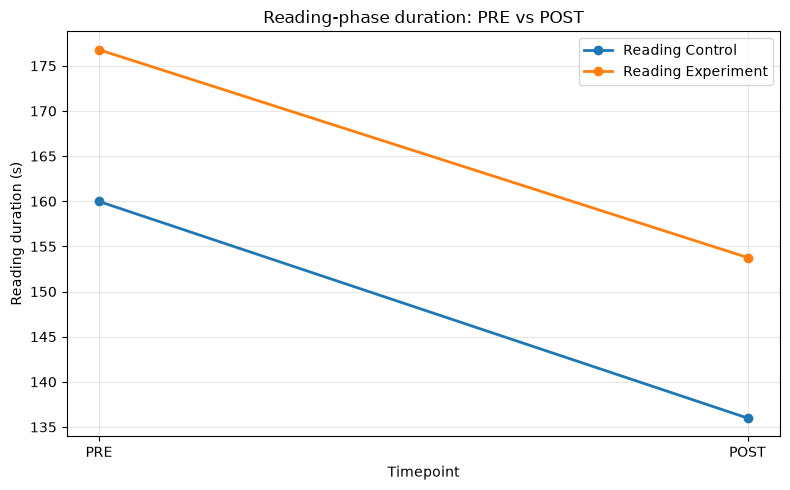

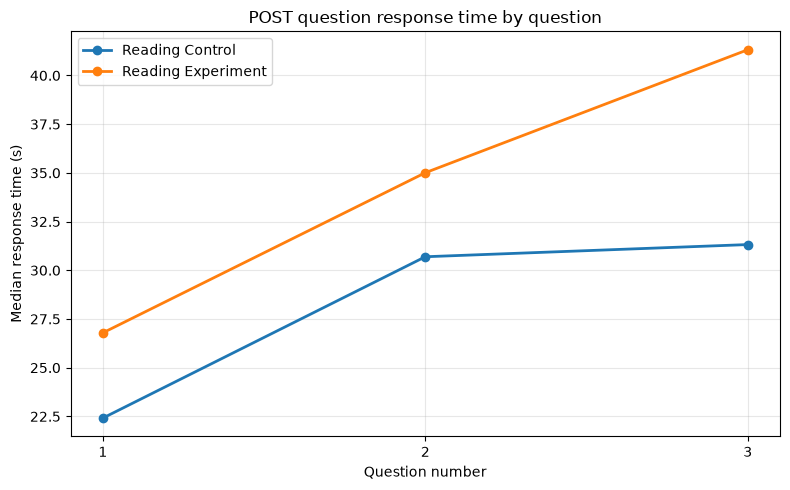

In [13]:
if not phase_summary.empty:
    fig, ax = plt.subplots(figsize=(8, 5))
    for group, d in phase_summary.groupby("group"):
        d = d.set_index("timepoint").reindex(["PRE", "POST"])
        ax.plot(["PRE", "POST"], d["mean_duration_s"], marker="o", linewidth=2, label=group)
    ax.set(title="Reading-phase duration: PRE vs POST",
           xlabel="Timepoint", ylabel="Reading duration (s)")
    ax.grid(True, alpha=.3); ax.legend()
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / "01_reading_phase_duration_pre_post.png", dpi=220)
    plt.show()

if not post_q_summary.empty:
    fig, ax = plt.subplots(figsize=(8, 5))
    for group, d in post_q_summary.groupby("group"):
        d = d.sort_values("question_number")
        ax.plot(d["question_number"], d["median_response_time_s"], marker="o", linewidth=2, label=group)
    ax.set(title="POST question response time by question",
           xlabel="Question number", ylabel="Median response time (s)")
    ax.set_xticks([1, 2, 3]); ax.grid(True, alpha=.3); ax.legend()
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / "02_post_question_response_time.png", dpi=220)
    plt.show()

## 13. Outlier screening for reading duration and POST question response time

Outlier flags are for review only; they are not automatic exclusion criteria. Reading duration and question response time are screened separately because they represent different phases and scales.

In [14]:
def add_iqr_mad_flags(data, value_col, group_cols):
    pieces = []
    for keys, d in data.groupby(group_cols, dropna=False):
        d = d.copy()
        x = pd.to_numeric(d[value_col], errors="coerce")
        q1, q3 = x.quantile([.25, .75])
        iqr = q3 - q1
        d["iqr_lower_s"] = max(0, q1 - 1.5*iqr)
        d["iqr_upper_s"] = q3 + 1.5*iqr
        d["flag_iqr"] = (x < d["iqr_lower_s"]) | (x > d["iqr_upper_s"])
        med = x.median()
        mad = (x - med).abs().median()
        d["robust_mad_z"] = (0.67448975*(x-med)/mad) if pd.notna(mad) and mad > 0 else np.nan
        d["flag_mad"] = d["robust_mad_z"].abs() > 3.5
        d["flag_any_outlier"] = d["flag_iqr"] | d["flag_mad"]
        pieces.append(d)
    return pd.concat(pieces, ignore_index=True) if pieces else data.copy()

phase_outliers = add_iqr_mad_flags(valid_phase, "reading_duration_s", ["group", "timepoint"])
phase_outliers.to_csv(RESULTS_DIR / "reading_phase_duration_outlier_review.csv", index=False)
if not post_question_pairs.empty:
    qout = post_question_pairs.loc[post_question_pairs.positive_response_time].copy()
    qout = add_iqr_mad_flags(qout, "question_response_time_s", ["group", "question_number"])
    qout.to_csv(RESULTS_DIR / "reading_post_question_rt_outlier_review.csv", index=False)
    print("Flagged POST question RT rows:", int(qout.flag_any_outlier.sum()))
print("Flagged reading-phase duration rows:", int(phase_outliers.flag_any_outlier.sum()))
display(phase_outliers.loc[phase_outliers.flag_any_outlier].head(20))

Flagged POST question RT rows: 2
Flagged reading-phase duration rows: 3


,subject,group,timepoint,reading_id,start_reading_onset_s,end_reading_onset_s,reading_duration_s,phase_qc,iqr_lower_s,iqr_upper_s,flag_iqr,robust_mad_z,flag_mad,flag_any_outlier
29,sub-Re02,Reading Experiment,POST,NaN,0.996094,277.777344,276.781250,PASS,38.328125,227.453125,True,4.121020,True,True
30,sub-Re03,Reading Experiment,POST,R1,0.996094,438.714844,437.718750,PASS,38.328125,227.453125,True,8.557320,True,True
48,sub-Re03,Reading Experiment,PRE,R2,0.996094,506.648438,505.652344,PASS,0.000000,343.203125,True,7.544421,True,True


## 14. Run summary, quality checks and interpretation guardrails

The final status distinguishes completed calculations from source-data limitations. Missing event files remain missing; PRE question RTs and answer correctness are not inferred from data that do not contain the required information.

In [15]:
run_summary = {
    "project_root": str(PROJECT_ROOT),
    "reading_participant_folders": len(subjects),
    "reading_control_folders": sum(reading_group(s) == "Reading Control" for s in subjects),
    "reading_experiment_folders": sum(reading_group(s) == "Reading Experiment" for s in subjects),
    "expected_event_files": len(manifest),
    "event_files_found": int(manifest.file_found.sum()),
    "event_files_missing": int((~manifest.file_found).sum()),
    "decoded_event_rows": len(decoded),
    "event_code_count_mismatches": int(mapping_audit.mapping_status.eq("COUNT_MISMATCH").sum()) if len(mapping_audit) else np.nan,
    "recordings_without_subject_timepoint_tag_block": int(mapping_audit.loc[mapping_audit.mapping_status.eq("NO_SUBJECT_TIMEPOINT_TAG_BLOCK"), ["subject", "timepoint"]].drop_duplicates().shape[0]) if len(mapping_audit) else np.nan,
    "valid_reading_phase_records": len(valid_phase),
    "balanced_pre_post_duration_participants": len(phase_wide),
    "reading_speed_records": int(speed.reading_speed_wpm.notna().sum()) if "speed" in globals() else 0,
    "all_passage_word_counts_manually_verified": bool(all_counts_verified) if "all_counts_verified" in globals() else False,
    "post_question_answer_pairs": len(post_question_pairs),
    "post_question_pairing_review_records": int(post_question_audit.pairing_qc.ne("PASS").sum()) if len(post_question_audit) else np.nan,
    "output_directory": str(RESULTS_DIR)
}
display(pd.DataFrame([run_summary]).T.rename(columns={0: "value"}))
pd.DataFrame([run_summary]).to_csv(RESULTS_DIR / "reading_event_analysis_run_summary.csv", index=False)

completion = pd.DataFrame([
    ["Reading event decoding", "COMPLETE" if len(decoded) else "REVIEW", f"{len(decoded)} decoded event rows"],
    ["Workbook occurrence mapping", "REVIEW" if len(mapping_audit) and mapping_audit.mapping_status.eq("COUNT_MISMATCH").any() else "PASS WITH DOCUMENTED GAP",
     f"{int(mapping_audit.mapping_status.eq('COUNT_MISMATCH').sum()) if len(mapping_audit) else 0} count mismatches; missing subject/timepoint tag blocks reported separately"],
    ["Reading phase duration", "COMPLETE" if len(valid_phase) else "REVIEW", f"{len(valid_phase)} valid phase records"],
    ["Balanced PRE–POST duration analysis", "COMPLETE" if len(phase_wide) else "REVIEW", f"{len(phase_wide)} participants"],
    ["POST question-answer response time", "COMPLETE" if len(post_question_pairs) else "NOT AVAILABLE / REVIEW",
     f"{len(post_question_pairs)} pairs"],
    ["PRE question-level response time", "NOT AVAILABLE BY DESIGN", "No PRE question-onset event markers"],
    ["Answer correctness", "NOT AVAILABLE", "Answer key / scoring source required"],
    ["Reading speed", "PROVISIONAL — OCR COUNTS" if not all_counts_verified else "WORD COUNTS VERIFIED", f"{int(speed.reading_speed_wpm.notna().sum()) if "speed" in globals() else 0} WPM records; six passage counts require manual verification"],
    ["Missing event files", "REVIEW IF ANY", f"{int((~manifest.file_found).sum())} missing"],
], columns=["component", "status", "evidence"])
display(completion)
completion.to_csv(RESULTS_DIR / "reading_event_analysis_completion_status.csv", index=False)

print("\\nINTERPRETATION GUARDRAILS")
print("- Lower POST−PRE duration means a shorter reading phase; it does not automatically mean better comprehension.")
print("- Reading speed is length-normalised using passage-specific word counts; OCR-derived counts remain provisional until manually verified.")
print("- PRE and POST use different passages; WPM does not adjust for passage difficulty or comprehension.")
print("- PRE question RT is not computable from the exported markers.")
print("- Answer 1/2/3 is a selected option, not correctness.")
print("- Use participants, not questions or EEG channels, as independent units for group inference.")


,value
project_root,/Users/ananyosen/Documents/Term Project
reading_participant_folders,35
reading_control_folders,16
reading_experiment_folders,19
expected_event_files,70
event_files_found,65
event_files_missing,5
decoded_event_rows,430
event_code_count_mismatches,0
recordings_without_subject_timepoint_tag_block,2


,component,status,evidence
0,Reading event decoding,COMPLETE,430 decoded event rows
1,Workbook occurrence mapping,PASS WITH DOCUMENTED GAP,0 count mismatches; missing subject/timepoint ...
2,Reading phase duration,COMPLETE,63 valid phase records
3,Balanced PRE–POST duration analysis,COMPLETE,28 participants
4,POST question-answer response time,COMPLETE,105 pairs
5,PRE question-level response time,NOT AVAILABLE BY DESIGN,No PRE question-onset event markers
6,Answer correctness,NOT AVAILABLE,Answer key / scoring source required
7,Reading speed,PROVISIONAL — OCR COUNTS,61 WPM records; six passage counts require man...
8,Missing event files,REVIEW IF ANY,5 missing


\nINTERPRETATION GUARDRAILS
- Lower POST−PRE duration means a shorter reading phase; it does not automatically mean better comprehension.
- Reading speed is length-normalised using passage-specific word counts; OCR-derived counts remain provisional until manually verified.
- PRE and POST use different passages; WPM does not adjust for passage difficulty or comprehension.
- PRE question RT is not computable from the exported markers.
- Answer 1/2/3 is a selected option, not correctness.
- Use participants, not questions or EEG channels, as independent units for group inference.


## Revision notes — 16 November 2026

- Fixed Question/Answer number parsing so `Question 1–3` and `Answer 1–3` are converted to numeric labels.
- Added a safe fallback for globally documented Reading question/answer event codes when a participant/timepoint block is absent from the workbook.
- Condition code `1` is interpreted as the reading start/end pair only for recordings with exactly two such markers and no participant/timepoint workbook block, consistent with the workbook's documented use of condition 1.
- Missing participant/timepoint workbook blocks are now reported separately from true event-code count mismatches. Reading ID remains unknown where the workbook does not provide it.
- Re-run the notebook from the first cell to regenerate all outputs. Existing saved outputs have been cleared to prevent old, incorrect empty question summaries from being mistaken for current results.


## Revision notes — passage metadata update

- Added the six actual passage titles and timepoint-specific word-count estimates from OCR of the supplied `Reading.zip` images.
- PRE and POST R1/R2/R3 are treated as six distinct passages, not as identical repeated texts.
- Added participant-level WPM calculations, group summaries and paired PRE–POST WPM change exports.
- WPM inferential tests are intentionally gated until all six word counts are manually verified (`manually_verified=True` in `reading_text_word_count_metadata.csv`).
- OCR word counts are provisional and may include/exclude punctuation, headings or OCR errors. Verify the counts using a consistent word-counting rule before final reporting.
- Different passages may differ in difficulty; word-count normalisation alone does not establish passage equivalence.
